Este código foi criado para desenvolver um modelo de CNN para quantificar células marcadas com fluorescencia, indicando presença da proteína na célula.

# Imports data structuring

In [29]:
#organização dos arquivos
import os
#salvar/carregar arquivos em diferentes formatos
import joblib
#organizando os arquivos de forma aleatória
import random
#gerar gráfico
import matplotlib
#estruturação dos dados
import numpy as np
#gerar gráfico
import seaborn as sns
#gerar gráfico
import matplotlib.pyplot as plt
#gerar imagem
import matplotlib.image as mpimg

# CNN template import

In [30]:
#modelo de revisão redes neurais - cnn
from keras.models import Sequential
from keras.utils import to_categorical # Import directly from keras.utils
from util import meus_uteis, timeProcess, mask_corr_graphic, printLis
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report
from keras.layers import Dense, Conv2D, MaxPooling2D, Dropout, Flatten

Documents from different files will be stored in this directory

In [34]:
diretorio = "./data/realcadas_verde_HUVEC/save/"
lista_dados = os.listdir(diretorio) #listando os arquivos dessa pasta
printLis(lista_dados) #printando as diferentes listas

-------------
-=< Lista >=-
-------------
0 -> imagens_HUVEC_validação_10%_fluore_2026-10-18.gz
1 -> imagens_treino_fluore_HUVEC_100_75_50_25_2026-10-18.gz
2 -> lista_imagem_100_jitter_regre_HUVEC_realce_2026-10-18.gz
3 -> lista_imagem_100_motion_regre_HUVEC_realce_2026-10-18.gz
4 -> lista_imagem_100_resized_regre_HUVEC_fluo_MFI_2026-10-18.gz
5 -> lista_img_100_resized_regre_campo_claro_2026-10-18.gz
6 -> lista_rotulos_100_angulo_regre_balb-roseta_2026-10-18.gz
7 -> lista_rotulos_100_angulo_regre_HUVEC_fluo_MFI_2026-10-18.gz
8 -> lista_rotulos_100_resized_regre_HUVEC_fluo_MFI_2026-10-18.gz
9 -> lista_rotulo_100_angulo_regre_balb-roseta_2026-10-18.gz
10 -> modelo_fluore_HUVEC_100_75_50_25_2026-10-18.keras
11 -> rotulos_treino_fluore_HUVEC_100_75_50_25_2026-10-18.gz
12 -> rótulos_HUVEC_validação_10%_fluore_2026-10-18.gz


Lists of all images in each file

## x = features/images

In [32]:
#0 - 100% somando todas as imagens de diferentes tamanho
X_cem = joblib.load(diretorio+ '/' + lista_dados[2])

# 2 - 75%
X_setcin = joblib.load(diretorio+ '/' + lista_dados[3])

# # 4 - 50%
X_cinq = joblib.load(diretorio+ '/' + lista_dados[4])

# # 6 - 25%
# X_vincin = joblib.load(diretorio+ '/' + lista_dados[6])

x = np.asarray(list(X_cem) + list(X_setcin) + list(X_cinq))

x.shape

(456, 300, 300, 3)

# y = labels

Opening the labels that were saved in the preparation of the images

In [35]:
#1 - 100% somando todos os rótulos de diferentes tamanho
y_cem = joblib.load(diretorio+ '/' + lista_dados[6])

#3 - 75%
# y_setcin = joblib.load(diretorio+ '/' + lista_dados[6])

# #4 - 50%
# y_cinq = joblib.load(diretorio+ '/' + lista_dados[5])

# #7 - 25%
# y_vincin = joblib.load(diretorio+ '/' + lista_dados[7])

y = np.asarray(list(y_cem))

y.shape

(456,)

#Separando dados de validação

In [36]:
#Train and test split datasets for CNN model
#função que separa as imagens em teste e treino
from sklearn.model_selection import train_test_split

In [40]:
zeros = list(np.zeros(411))
ones = list(np.ones(45))
lista = np.array(zeros + ones)
#lista

In [41]:
random.shuffle(lista)
lista_valida = [True if i == 1 else False for i in lista]
lista_treino_test = [False if i == 1 else True for i in lista]
#np.array(lista_valida)

In [42]:
#imagens
x_valida = x[lista_valida]
x_treino_test = x[lista_treino_test]

print(x_valida.shape)
print(x_treino_test.shape)

(45, 300, 300, 3)
(411, 300, 300, 3)


In [43]:
#rótulos
y_valida = y[lista_valida]
y_treino_test = y[lista_treino_test]

print(y_valida.shape)
print(y_treino_test.shape)

(45,)
(411,)


In [44]:
data = timeProcess()[1]
#Salvando 10$ das imagens para validação
joblib.dump(x_valida, f'{diretorio}imagens_HUVEC_validação_10%_fluore_'+data+'.gz')
joblib.dump(y_valida, f'{diretorio}rótulos_HUVEC_validação_10%_fluore_'+data+'.gz')

['./data/realcadas_verde_HUVEC/save/rótulos_HUVEC_validação_10%_fluore_2026-10-18.gz']

Test and training separation from a library.

In [45]:
X_train, X_test, y_train, y_test = train_test_split(x_treino_test, y_treino_test, test_size=0.3, random_state=0)
#variáveis recebem o número de imagens para tes e treino
print(f'{X_train.shape} \n{X_test.shape} \n{y_train.shape} \n{y_test.shape}')

(287, 300, 300, 3) 
(124, 300, 300, 3) 
(287,) 
(124,)


In [46]:
y_train = y_train.astype(float)
y_test = y_test.astype(float)
# print(int_array)
# print(int_array.dtype)


In [47]:
#salvando os resultados de treino e teste
joblib.dump(X_test, f'{diretorio}imagens_treino_fluore_HUVEC_100_75_50_25_'+data+'.gz')
joblib.dump(y_test, f'{diretorio}rotulos_treino_fluore_HUVEC_100_75_50_25_'+data+'.gz')

['./data/realcadas_verde_HUVEC/save/rotulos_treino_fluore_HUVEC_100_75_50_25_2026-10-18.gz']

### Model determination

In [48]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

modelo = Sequential()

# Bloco 1
modelo.add(Conv2D(32, (3,3), activation='relu', padding='same', input_shape=X_train[0].shape))
modelo.add(BatchNormalization())
modelo.add(MaxPooling2D(pool_size=(2,2)))

# Bloco 2
modelo.add(Conv2D(64, (3,3), activation='relu', padding='same'))
modelo.add(BatchNormalization())
modelo.add(MaxPooling2D(pool_size=(2,2)))

# Bloco 3
modelo.add(Conv2D(128, (3,3), activation='relu', padding='same'))
modelo.add(BatchNormalization())
modelo.add(MaxPooling2D(pool_size=(2,2)))

# Flatten
modelo.add(Flatten())

# Camadas densas
modelo.add(Dense(128, activation='relu'))
modelo.add(Dropout(0.3))

modelo.add(Dense(64, activation='relu'))
modelo.add(Dropout(0.2))

# Saída de regressão
modelo.add(Dense(1, activation='linear'))

modelo.compile(optimizer='adam', loss='mse', metrics=['mean_squared_error'])
modelo.summary()


Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_3 (Conv2D)           (None, 300, 300, 32)      896       
                                                                 
 batch_normalization_3 (Batc  (None, 300, 300, 32)     128       
 hNormalization)                                                 
                                                                 
 max_pooling2d_3 (MaxPooling  (None, 150, 150, 32)     0         
 2D)                                                             
                                                                 
 conv2d_4 (Conv2D)           (None, 150, 150, 64)      18496     
                                                                 
 batch_normalization_4 (Batc  (None, 150, 150, 64)     256       
 hNormalization)                                                 
                                                      

# Training and testing epochs

In [49]:
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.callbacks import ModelCheckpoint

In [50]:
es = EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)

lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.3,
    patience=5,
    min_lr=1e-6
)

history = modelo.fit(
    X_train, y_train,
    validation_data=(X_test, y_test),
    epochs=200,
    batch_size=32,
    callbacks=[es, lr],
    verbose=2
)

Epoch 1/200
9/9 - 16s - loss: 4321.6309 - mean_squared_error: 4321.6309 - val_loss: 11602.9727 - val_mean_squared_error: 11602.9727 - lr: 0.0010 - 16s/epoch - 2s/step
Epoch 2/200
9/9 - 18s - loss: 1080.9846 - mean_squared_error: 1080.9846 - val_loss: 2106.7234 - val_mean_squared_error: 2106.7234 - lr: 0.0010 - 18s/epoch - 2s/step
Epoch 3/200
9/9 - 19s - loss: 1199.6464 - mean_squared_error: 1199.6464 - val_loss: 1352.6425 - val_mean_squared_error: 1352.6425 - lr: 0.0010 - 19s/epoch - 2s/step
Epoch 4/200
9/9 - 27s - loss: 1059.5692 - mean_squared_error: 1059.5692 - val_loss: 1498.2329 - val_mean_squared_error: 1498.2329 - lr: 0.0010 - 27s/epoch - 3s/step
Epoch 5/200
9/9 - 22s - loss: 563.0353 - mean_squared_error: 563.0353 - val_loss: 553.9202 - val_mean_squared_error: 553.9202 - lr: 0.0010 - 22s/epoch - 2s/step
Epoch 6/200
9/9 - 21s - loss: 343.9471 - mean_squared_error: 343.9471 - val_loss: 676.9987 - val_mean_squared_error: 676.9987 - lr: 0.0010 - 21s/epoch - 2s/step
Epoch 7/200
9/9 

In [51]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np

# Faça as predições
pred = modelo.predict(X_test)

# Converte para 1D caso necessário
y_true = y_test.ravel()
y_pred = pred.ravel()

# Métricas
r2 = r2_score(y_true, y_pred)
mae = mean_absolute_error(y_true, y_pred)
mse = mean_squared_error(y_true, y_pred)
rmse = np.sqrt(mse)

# Exibição formatada
print(f"R²: {r2:.4f}")
print(f"MAE: {mae:.4f}")
print(f"MSE: {mse:.4f}")
print(f"RMSE: {rmse:.4f}")


4/4 [==============================] - 1s 255ms/step
R²: -11.0247
MAE: 0.1190
MSE: 0.0370
RMSE: 0.1923


In [52]:
print(f"{r2 * 100:.2f}% R² Score")
print(f"{mae:.2f} MAE (Erro médio absoluto)")
print(f"{mse:.2f} MSE (Erro médio quadrático)")
print(f"{rmse:.2f} RMSE (Raiz do erro médio quadrático)")


-1102.47% R² Score
0.12 MAE (Erro médio absoluto)
0.04 MSE (Erro médio quadrático)
0.19 RMSE (Raiz do erro médio quadrático)


## Accuracy Assessment

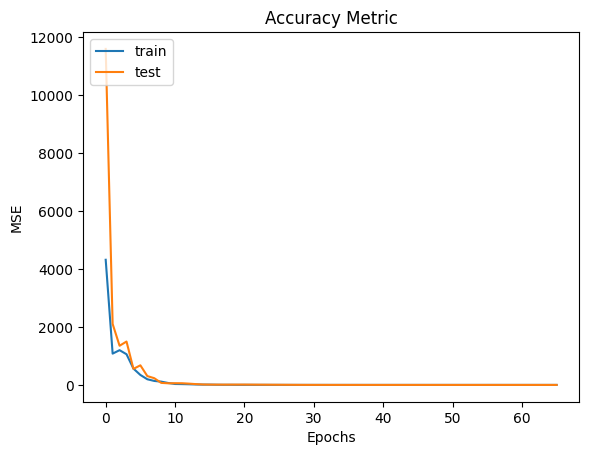

In [53]:
#gráfico avaliando a acurácia a partir de treino e teste
plt.plot(history.history['mean_squared_error'])
plt.plot(history.history['val_mean_squared_error'])
plt.title('Accuracy Metric')
plt.ylabel('MSE')
plt.xlabel('Epochs')
plt.legend(['train', 'test'], loc='upper left')
plt.show()

4/4 [==============================] - 1s 291ms/step


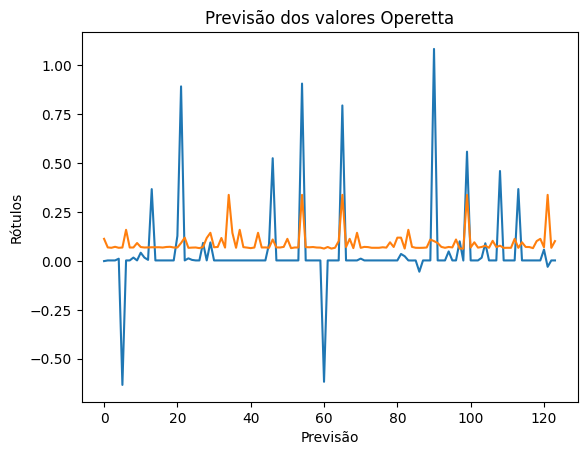

In [54]:
#avaliando a previsão do modelo com os rótulos
prev = modelo.predict(X_test)
plt.title('Previsão dos valores Operetta')
plt.ylabel('Rótulos')
plt.xlabel('Previsão')
plt.plot(prev)#azul - o que o modelo previu
plt.plot(y_test)#laranja - o que se sabe - observado
plt.show()

In [55]:
# Qualit model analisys
from sklearn.metrics import r2_score,mean_absolute_error, mean_squared_error, mean_squared_log_error, median_absolute_error

In [56]:
#buscando pelas métricas
print(f"{round(r2_score(y_test, prev) * 100, 2)}% r2_score") #raíz quadrada
print(f"{round(mean_absolute_error(y_test, prev), 2)} Erro médio absoluto")
print(f"{round(mean_squared_error(y_test, prev), 2)} Erro médio quadrático") #erro médio quadrático
# print(f"{round(median_absolute_error(y_test, prev), 2)}")#Erro médio absoluto sem %
#print(f"{round(median(y_test, prev), 2)} mediana") #erro médio quadrático

-1102.47% r2_score
0.12 Erro médio absoluto
0.04 Erro médio quadrático


In [57]:
# Métricas do modelo de regressão
r2 = r2_score(y_test, prev)
mae = mean_absolute_error(y_test, prev)
mse = mean_squared_error(y_test, prev)
rmse = np.sqrt(mse)

print(f"{round(r2 * 100, 2)}% R² score")
print(f"{round(mae, 2)} Mean Absolute Error (MAE)")
print(f"{round(mse, 2)} Mean Squared Error (MSE)")
print(f"{round(rmse, 2)} Root Mean Squared Error (RMSE)")

-1102.47% R² score
0.12 Mean Absolute Error (MAE)
0.04 Mean Squared Error (MSE)
0.19 Root Mean Squared Error (RMSE)


In [58]:
import numpy as np

def calculate_r_squared_manual(y_true, y_pred):
    """
    Calculates the coefficient of determination (R-squared) manually.

    Args:
        y_true (list or np.array): The true (observed) values.
        y_pred (list or np.array): The predicted values from the model.

    Returns:
        float: The R-squared value.
    """
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)

    # Calculate the mean of the true values
    y_true_mean = np.mean(y_true)

    # Calculate the Sum of Squares of Residuals (SS_res)
    ss_res = np.sum((y_true - y_pred) ** 2)

    # Calculate the Total Sum of Squares (SS_tot)
    ss_tot = np.sum((y_true - y_true_mean) ** 2)

    # Handle the case where SS_tot is zero (e.g., all y_true values are the same)
    if ss_tot == 0:
        return 1.0  # R-squared is 1 if there's no variance in y_true

    # Calculate R-squared
    r_squared = 1 - (ss_res / ss_tot)

    return r_squared

# === YOUR MODEL'S VALUES ===
# y_test = seus valores reais
# prev   = previsões geradas pelo modelo (modelo.predict)

r_squared_value = calculate_r_squared_manual(y_test, prev)
print(f"Manual R²: {r_squared_value}")


Manual R²: -1858.6847679171601


In [59]:
import numpy as np
print("Variância:", np.var(y_test))
print("Desvio Padrão:", np.std(y_test))
print("Amplitude:", np.ptp(y_test))


Variância: 0.003076663381178135
Desvio Padrão: 0.055467678707316885
Amplitude: 0.274592


In [60]:
modelo.save(f'{diretorio}modelo_fluore_HUVEC_100_75_50_25_'+data+'.keras')